In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l


class Residual(nn.Module):
    def __init__(self, input_channels, num_channels,
                 use_1x1conv=False, strides=1):
        super().__init__()
        # 第一个卷积层
        self.conv1 = nn.Conv2d(input_channels, num_channels,
                               kernel_size=3, padding=1, stride=strides)
        # 第二个卷积层
        self.conv2 = nn.Conv2d(num_channels, num_channels,
                               kernel_size=3, padding=1)
        # 如果使用1 x 1卷积以使得输入变换成需要的形状
        if use_1x1conv:
            self.conv3 = nn.Conv2d(input_channels, num_channels,
                                   kernel_size=1, stride=strides)
        else:
            self.conv3 = None
        # 对应第一个卷积层的批量规范化层
        self.bn1 = nn.BatchNorm2d(num_channels)
        # 对应第二个卷积层的批量规范化层
        self.bn2 = nn.BatchNorm2d(num_channels)

    def forward(self, X):
        # 第一层：卷积 -> 规范化 -> relu激活
        Y = F.relu(self.bn1(self.conv1(X)))
        # 第二层：卷积 -> 规范化
        Y = self.bn2(self.conv2(Y))
        # 如果要让输入变换成需要的形状
        if self.conv3:
            # 对X使用1 x 1卷积，以使输出成为需要的形状
            X = self.conv3(X)
        # 嵌套模型的实现，即对上一次训练后的模型进行嵌套
        Y += X
        # relu激活并输出
        return F.relu(Y)

d:\Anaconda\envs\ZZC\lib\site-packages\requests\__init__.py:109: RequestsDependencyWarning: urllib3 (2.1.0) or chardet (7.4.3)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


In [2]:
def resnet_block(input_channels, num_channels, num_residuals,
                 first_block=False):
    blk = []
    for i in range(num_residuals):
        if i == 0 and not first_block:
            blk.append(Residual(input_channels, num_channels,
                                use_1x1conv=True, strides=2))
        else:
            blk.append(Residual(num_channels, num_channels))
    return blk



In [3]:
b1 = nn.Sequential(nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3),
                   nn.BatchNorm2d(64), nn.ReLU(),
                   nn.MaxPool2d(kernel_size=3, stride=2, padding=1))

b2 = nn.Sequential(*resnet_block(64, 64, 2, first_block=True))
b3 = nn.Sequential(*resnet_block(64, 128, 2))
b4 = nn.Sequential(*resnet_block(128, 256, 2))
b5 = nn.Sequential(*resnet_block(256, 512, 2))

net = nn.Sequential(b1, b2, b3, b4, b5,
                    nn.AdaptiveAvgPool2d((1,1)),
                    nn.Flatten(), nn.Linear(512, 10))




In [ ]:
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader

lr, num_epochs, batch_size = 0.05, 10, 256 
resize = 96
trans = [transforms.ToTensor()]
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, resize=96)
d2l.train_ch6(net, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())

training on cpu


In [2]:
import torch

a = torch.randn((4,4))

In [3]:
a

tensor([[-1.1955,  1.7548, -0.9353,  1.4786],
        [ 0.3825,  0.7035, -1.1782, -1.2200],
        [ 0.6243, -0.5619,  0.2086, -1.5124],
        [ 1.5964,  1.2109, -0.3897, -1.5488]])

In [9]:
import re
import collections
import torch
from torch.utils.data import DataLoader, TensorDataset
from d2l import torch as d2l

def load_data_time_machine(batch_size, num_steps):
    url = "https://d2l-data.s3.us-west-2.amazonaws.com/timemachine.txt"
    data_dir = "./data"
    fname = d2l.download(url, data_dir)

    with open(fname, "r") as f:
        lines = f.readlines()

    tokens = []
    for line in lines:
        tokens.extend(
            re.sub("[^A-Za-z]+", " ", line).strip().lower()
        )

    vocab = d2l.Vocab(collections.Counter(tokens))
    corpus = [vocab[token] for token in tokens]

    num_batches = (len(corpus) - 1) // (batch_size * num_steps)
    corpus = corpus[: num_batches * batch_size * num_steps + 1]

    X = torch.tensor(corpus[:-1]).reshape(batch_size, -1)
    Y = torch.tensor(corpus[1:]).reshape(batch_size, -1)

    dataset = TensorDataset(X, Y)
    train_iter = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    return train_iter, vocab
import math
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

class RNNModelScratch:
    """从零开始实现的循环神经网络模型"""
    def __init__(self, vocab_size, num_hiddens, device,
                 get_params, init_state, forward_fn):
        self.vocab_size = vocab_size
        self.num_hiddens = num_hiddens
        self.params = get_params(vocab_size, num_hiddens, device)
        self.init_state = init_state
        self.forward_fn = forward_fn

    def __call__(self, X, state):
        X = F.one_hot(X.T, self.vocab_size).type(torch.float32)
        return self.forward_fn(X, state, self.params)

    def begin_state(self, batch_size, device):
        return self.init_state(batch_size, self.num_hiddens, device)


def grad_clipping(net, theta):
    """裁剪梯度"""
    if isinstance(net, nn.Module):
        params = [p for p in net.parameters() if p.requires_grad]
    else:
        params = net.params
    norm = torch.sqrt(sum(torch.sum((p.grad ** 2)) for p in params))
    if norm > theta:
        for param in params:
            param.grad[:] *= theta / norm


def train_epoch_ch8(net, train_iter, loss, updater, device, use_random_iter):
    state, timer = None, d2l.Timer()
    metric = d2l.Accumulator(2)

    for X, Y in train_iter:
        if state is None or use_random_iter:
            state = net.begin_state(batch_size=X.shape[0], device=device)
        else:
            if isinstance(net, nn.Module) and not isinstance(state, tuple):
                state.detach_()
            else:
                for s in state:
                    s.detach_()

        y = Y.T.reshape(-1)
        X, y = X.to(device), y.to(device)

        y_hat, state = net(X, state)
        l = loss(y_hat, y.long()).mean()

        if isinstance(updater, torch.optim.Optimizer):
            updater.zero_grad()
            l.backward()
            grad_clipping(net, 1)
            updater.step()
        else:
            l.backward()
            grad_clipping(net, 1)
            updater(batch_size=1)

        metric.add(l * y.numel(), y.numel())

    return math.exp(metric[0] / metric[1]), metric[1] / timer.stop()


def train_ch8(net, train_iter, vocab, lr, num_epochs, device,
              use_random_iter=False):
    loss = nn.CrossEntropyLoss()
    animator = d2l.Animator(xlabel='epoch', ylabel='perplexity',
                            legend=['train'], xlim=[10, num_epochs])

    if isinstance(net, nn.Module):
        updater = torch.optim.SGD(net.parameters(), lr)
    else:
        updater = lambda batch_size: d2l.sgd(net.params, lr, batch_size)

    def predict(prefix):
        from d2l import torch as d2l
        return d2l.predict_ch8(prefix, 50, net, vocab, device)

    for epoch in range(num_epochs):
        ppl, speed = train_epoch_ch8(
            net, train_iter, loss, updater, device, use_random_iter
        )
        if (epoch + 1) % 10 == 0:
            print(f'epoch {epoch + 1}, perplexity {ppl:.1f}, speed {speed:.1f} tokens/sec')
        animator.add(epoch + 1, [ppl])

In [11]:
import torch
from torch import nn
from d2l import torch as d2l
batch_size, num_steps = 32, 35
train_iter, vocab =load_data_time_machine(batch_size, num_steps)

def get_lstm_params(vocab_size,num_hiddens,device):
    num_inputs = num_outputs = vocab_size
    def normal(shape):
        return torch.randn(size=shape,device=device)*0.01
    
    def three():
        return (normal((num_inputs, num_hiddens)),
                normal((num_hiddens, num_hiddens)),
                torch.zeros(num_hiddens, device=device))
    # 都是以矩阵的方式传递            
    W_xi, W_hi, b_i = three()  # 输入门参数
    W_xf, W_hf, b_f = three()  # 遗忘门参数
    W_xo, W_ho, b_o = three()  # 输出门参数
    W_xc, W_hc, b_c = three()  # 候选记忆元参数
    # 输出层参
    w_hq = normal((num_hiddens, num_outputs))
    b_q = torch.zeros(num_outputs, device=device)
    #附加梯度
    params = [W_xi, W_hi, b_i, W_xf, W_hf, b_f, W_xo, W_ho, b_o, W_xc, W_hc,b_c, W_hq, b_q]
    for param in params:
        param.requires_grad_(True)
    return params
    
def init_lstm_state(batch_size,num_hiddens,device):
    return (torch.zeros((batch_size, num_hiddens), device=device), torch.zeros((batch_size, num_hiddens),device=device))

def lstm(inputs,state,params):
    [W_xi, W_hi, b_i, W_xf, W_hf, b_f, W_xo, W_ho, b_o, W_xc, W_hc, b_c,W_hq, b_q]  = params
    (H,c) = state
    outputs = []
    for X in inputs:
        I = torch.sigmoid((X @ W_xi) + (H @ W_hi) + b_i)
        F = torch.sigmoid((X @ W_xf) + (H @ W_hf) + b_f)
        O = torch.sigmoid((X @ W_xo) + (H @ W_ho) + b_o)
        C_tilda = torch.tanh((X @ W_xc) + (H @ W_hc) + b_c)
        C = F * C + I * C_tilda
        H = O * torch.tanh(C)
        Y = (H @ W_hq) + b_q
        outputs.append(Y)
    return torch.cat(outputs,dim=0),(H,C)


vocab_size, num_hiddens, device = len(vocab), 256, d2l.try_gpu()
num_epochs, lr = 500, 1
model = RNNModelScratch(len(vocab), num_hiddens, device, get_lstm_params,init_lstm_state, lstm)
d2l.train_ch8(model, train_iter, vocab, lr, num_epochs, device)

NameError: name 'W_hq' is not defined

In [6]:
import d2l
print(d2l.__version__)

1.0.3


In [12]:

import torch.nn as nn
vocab_size,num_hiddens,num_layers = 8, 256 , 2
lstm_layer = nn.LSTM(8,num_hiddens,num_layers)

In [17]:
print(lstm_layer)

LSTM(8, 256, num_layers=2)


In [5]:
import torch
import torch.nn as nn

embedding = nn.Embedding(10, 3) # an Embedding module containing 10 tensors of size 3
#input = torch.LongTensor([[1,2,4,5,6],[4,3,2,9,6]]) # a batch of 2 samples of 4 indices each
input = torch.LongTensor([[1,2,4,5],[4,3,2,9]]) # a batch of 2 samples of 4 indices each
e = embedding(input)


In [6]:
e

tensor([[[ 0.0651, -0.9870,  0.5915],
         [-0.1208, -1.0309,  0.2620],
         [-0.9255,  0.7318,  0.2618],
         [ 0.2599,  1.3015,  0.3415]],

        [[-0.9255,  0.7318,  0.2618],
         [-0.7873, -0.7363,  1.1699],
         [-0.1208, -1.0309,  0.2620],
         [ 0.5335, -0.5748, -1.4758]]], grad_fn=<EmbeddingBackward0>)

In [19]:
# 一下是注意力机制的代码
import torch
from torch import nn
from d2l import torch as d2l
n_train = 50 # 训练样本数
x_train, _ = torch.sort(torch.rand(n_train) * 5) # 排序后的训练样本
def f(x):
    return 2 * torch.sin(x) + x**0.8
y_train = f(x_train) + torch.normal(0.0, 0.5, (n_train,)) # 训练样本的输出
x_test = torch.arange(0, 5, 0.1) # 测试样本

y_truth = f(x_test) # 测试样本的真实输出
n_test = len(x_test) # 测试样本数
#n_test

def plot_kernel_reg(y_hat):
    d2l.plot(x_test, [y_truth, y_hat], 'x', 'y', legend=['Truth', 'Pred'],
        xlim=[0, 5], ylim=[-1, 5])  
    d2l.plt.plot(x_train, y_train, 'o', alpha=.5);


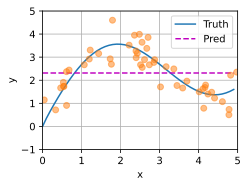

In [21]:
y_hat = torch.repeat_interleave(y_train.mean(), n_test)
plot_kernel_reg(y_hat)

In [29]:
import torch
#batch=2, num_queries=3, num_hiddens=4
# (2,3,4)
a = torch.tensor(
    [
        [0.1, -0.3,  0.5,  0.2],   # 第1个query的4维隐藏向量
        [0.4,  0.1, -0.2,  0.6],   # 第2个query的4维隐藏向量
        [-0.1, 0.3,  0.4, -0.5],   # 第3个query的4维隐藏向量
    ])


In [30]:
b = a.unsqueeze(1)
b

tensor([[[ 0.1000, -0.3000,  0.5000,  0.2000]],

        [[ 0.4000,  0.1000, -0.2000,  0.6000]],

        [[-0.1000,  0.3000,  0.4000, -0.5000]]])

In [ ]:
b = a.unsqueeze(0)


tensor([[ 0.1000, -0.3000,  0.5000,  0.2000],
        [ 0.4000,  0.1000, -0.2000,  0.6000],
        [-0.1000,  0.3000,  0.4000, -0.5000]])

In [36]:
print(b)
print(b[0])
print(b[0][0][0])

tensor([[[ 0.1000, -0.3000,  0.5000,  0.2000],
         [ 0.4000,  0.1000, -0.2000,  0.6000],
         [-0.1000,  0.3000,  0.4000, -0.5000]]])
tensor([[ 0.1000, -0.3000,  0.5000,  0.2000],
        [ 0.4000,  0.1000, -0.2000,  0.6000],
        [-0.1000,  0.3000,  0.4000, -0.5000]])
tensor(0.1000)


In [37]:
x = torch.tensor([1, 2, 3, 4])
ee = torch.unsqueeze(x, 0)
ee1 = torch.unsqueeze(x, 1)

In [53]:
print(ee1,'\n',ee)

tensor([[1],
        [2],
        [3],
        [4]]) 
 tensor([[1, 2, 3, 4]])


False